**EDA (Charges, Smokers vs Non-smokers, Correlation Map) by:** M3 (Ogunsanya Mary Fiyinfoluwa).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("../data/insurance_clean.csv")

In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1337 non-null   int64  
 1   sex       1337 non-null   str    
 2   bmi       1337 non-null   float64
 3   children  1337 non-null   int64  
 4   smoker    1337 non-null   str    
 5   region    1337 non-null   str    
 6   charges   1337 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.4 KB


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [4]:
## numerical summary
df['charges'].describe()

count     1337.000000
mean     13279.121487
std      12110.359656
min       1121.873900
25%       4746.344000
50%       9386.161300
75%      16657.717450
max      63770.428010
Name: charges, dtype: float64

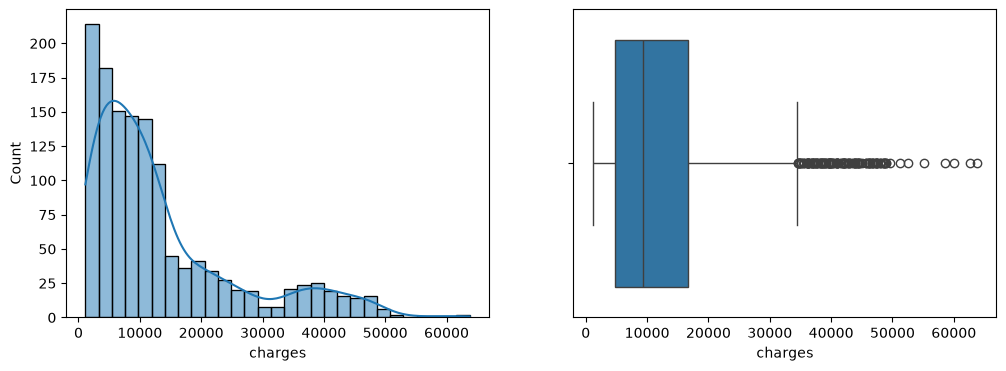

In [5]:
ig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['charges'], kde=True, ax=ax[0]) ##Are most people paying low charges, high charges, or something in between?
sns.boxplot(x=df['charges'], ax=ax[1])  ##Are there unusually high charges?
plt.show()

Charges range from about 1,122 to 63,770, with a mean of about 13,279 and a median of about 9,386.
- The mean is higher than the median, so the data is right-skewed: most people pay lower charges, and a small group pays very high ones.
- The middle 50% of people pay between about 4,746 and 16,658.
- - The histogram also shows a second, smaller cluster of charges between
  roughly 35,000 and 50,000. This suggests there is a distinct group of
  people with much higher costs, rather than just a few random extreme values.
- The outliers on the boxplot are numerous and make up a visible group,
  consistent with that second cluster.

**Hypothesis to test next:** this high-charge group may be explained by
smoking status. This is examined in the next section.

In [6]:
## smokers vs non smokers
df['smoker'].value_counts()
df.groupby('smoker')['charges'].agg(['mean', 'median', 'max'])

,mean,median,max
smoker,,,
no,8440.660307,7345.72660,36910.60803
yes,32050.231832,34456.34845,63770.42801


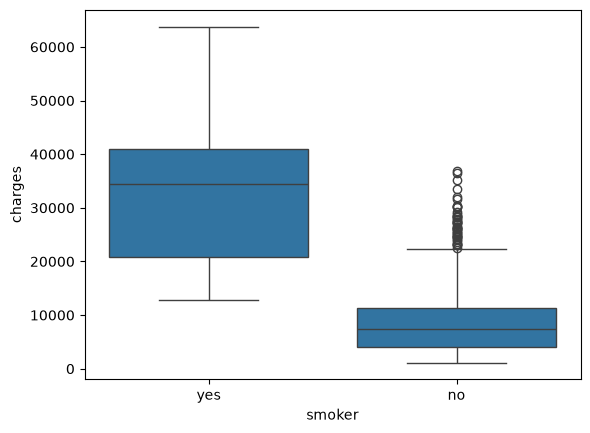

In [7]:
sns.boxplot(x='smoker', y='charges', data=df)
plt.show()

In [8]:
print(df['smoker'].value_counts())

smoker
no     1063
yes     274
Name: count, dtype: int64


## Smokers vs Non-smokers

Earlier, the charges distribution showed a second group of people with very high charges. Here we check whether smoking explains it.

- Out of 1,337 people, 274 are smokers (about 20%), so smokers are the smaller group.
- Smokers pay far more: the average charge is about 32,050, compared with about 8,441 for non-smokers (roughly 3.8 times higher).
- The two groups barely overlap. Even the lowest smoker charges (around 13,000) are higher than what most non-smokers pay (the top of their box is around 11,300).
- Smokers' charges are also more spread out, reaching about 63,770, so other factors like age or BMI probably play a part.
- Some non-smokers have high outliers (up to about 37,000), so smoking is not the only reason for high charges.

**Takeaway:** the high-charge cluster is mostly made up of smokers. Smoking status is one of the strongest factors behind charges and should be a key feature in any model.

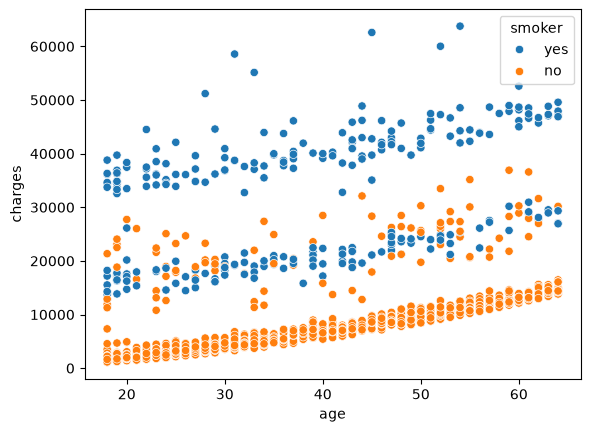

In [9]:
sns.scatterplot(x='age', y='charges', hue='smoker', data=df)
plt.show()

### Age and smoking status

To check whether the smoker effect holds across ages, we plotted charges against age, coloured by smoking status.

- Charges rise with age for both smokers and non-smokers.
- Smokers pay more at every age, from 18 to 64.
- The data forms three bands: non-smokers mostly fill the bottom, smokers mostly fill the top, and the middle is a mix of both.
- That mixed middle band explains the high non-smoker charges (outliers) seen earlier.
- The gap between the smoker bands suggests another factor, such as BMI, may also affect charges.

**Takeaway:** smoking status raises charges at every age, and age pushes charges up on top of that.

In [10]:
## correlation map
df_encoded = pd.get_dummies(df, drop_first=True)
corr = df_encoded.corr()

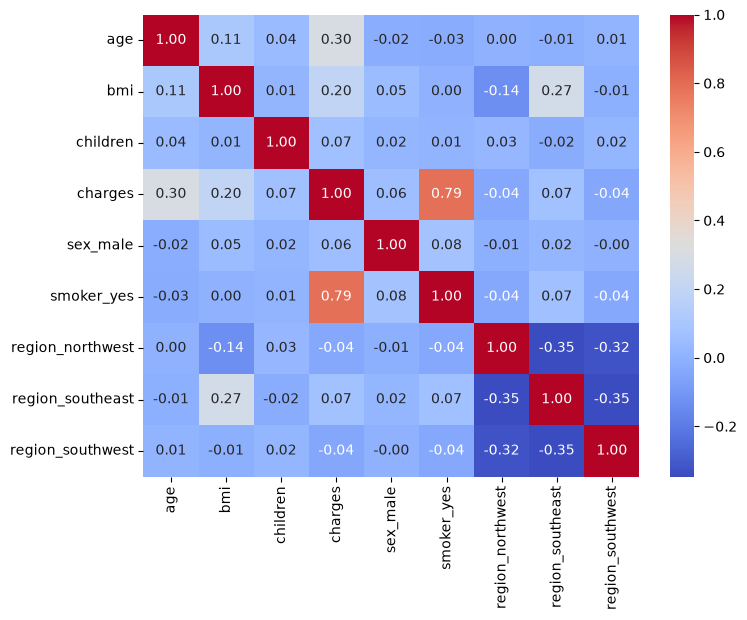

In [11]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [12]:
corr['charges'].sort_values(ascending=False)

charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64

## Correlation Map

To see which variables relate most to charges, we converted the text columns (sex, smoker, region) into 0/1 columns and plotted a correlation heatmap.

- **Smoking status is by far the strongest factor** (correlation 0.79 with charges), which confirms what we saw in the smoker analysis.
- **Age is second** (0.30): older people tend to pay more.
- **BMI has a weaker link** (0.20).
- **Children, sex and region show almost no relationship** with charges (all between -0.04 and 0.07).
- The strong negative values between the region columns come from how the encoding splits one column into several, so they are not a real finding.

**Takeaway:** smoker status, age and BMI are the most useful features for predicting charges. Correlation only captures straight-line relationships and does not prove cause and effect, so the model should be checked further.

## Summary of Findings 

- Charges are right-skewed, with a second cluster of very high values.
- Smokers pay about 3.8 times more than non-smokers on average, at every age.
- Smoking is the strongest predictor of charges, followed by age and BMI.
- Sex, number of children and region add little on their own.


In [13]:
print(df.shape)

(1337, 7)
